# 05 Customer map (ML6)

Owner: Jeevan Mandala (ML Engineer)

Each customer is projected onto the first 2 SVD components and grouped with k-means. We take the number of groups, between 3 and 6, that has the best silhouette score. Each group is described by what it buys more than the average customer does, and by its countries.

Only row positions in the matrix are used, so no customer ID is printed, plotted or saved.

In [6]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from recommend import load_processed, fit_svd, SEED

pd.set_option("display.max_colwidth", 140)
A, customer_index, product_index, eval_pairs = load_processed()
description = product_index["Description"].to_numpy()
print("Matrix:", A.shape)

Matrix: (5471, 3686)


## Number of groups

In [7]:
svd2 = fit_svd(A, 2)
Z = svd2.transform(A)              # customer factors U S, shape (customers, 2)
Z_std = StandardScaler().fit_transform(Z)

scores = {}
for n in range(3, 7):
    labels_n = KMeans(n_clusters=n, n_init=10, random_state=SEED).fit_predict(Z_std)
    scores[n] = silhouette_score(Z_std, labels_n)
silhouettes = pd.Series(scores, name="silhouette").round(3)
print(silhouettes.to_string())

N_GROUPS = int(silhouettes.idxmax())
labels = KMeans(n_clusters=N_GROUPS, n_init=10, random_state=SEED).fit_predict(Z_std)
print("Groups used:", N_GROUPS)

volume = np.asarray(A.sum(axis=1)).ravel()
print("|corr| of component 1 with total purchase value:", round(abs(np.corrcoef(Z[:, 0], volume)[0, 1]), 3))

3    0.643
4    0.623
5    0.584
6    0.520
Groups used: 3
|corr| of component 1 with total purchase value: 0.968


## Profile of each group

For each group we show its size, how many different products its customers buy, their average total purchase value (a sum of log values, not money) and the main countries. There are two product lists, both based on the share of group members who bought the product. most_bought is the 5 products with the biggest share. distinctive only looks at products bought by at least 5% of the group and takes the 5 with the highest ratio of share in this group to share in everyone else. We use the ratio because a group that holds most of the customers looks a lot like the overall average.

In [8]:
bought = (A > 0).astype(np.float32).tocsr()
profiles = []
for g in range(N_GROUPS):
    in_group = labels == g
    members = np.where(in_group)[0]
    share_in = np.asarray(bought[members].mean(axis=0)).ravel()
    share_out = np.asarray(bought[np.where(~in_group)[0]].mean(axis=0)).ravel()
    ratio = np.where(share_in >= 0.05, share_in / (share_out + 0.005), 0)
    most_bought = [description[j] for j in np.argsort(-share_in)[:5]]
    distinctive = [description[j] for j in np.argsort(-ratio)[:5]]
    block = A[members]
    countries = customer_index.loc[members, "Country"].value_counts(normalize=True).head(3)
    profiles.append({
        "group": g,
        "customers": len(members),
        "share_%": round(len(members) / A.shape[0] * 100, 1),
        "avg_products_bought": round(block.getnnz(axis=1).mean(), 1),
        "avg_total_purchase_value": round(float(np.asarray(block.sum(axis=1)).mean()), 1),
        "most_bought": "; ".join(most_bought),
        "distinctive": "; ".join(distinctive),
        "main_countries": ", ".join(f"{c} {s * 100:.0f}%" for c, s in countries.items()),
    })
profile_table = pd.DataFrame(profiles)
profile_table


,group,customers,share_%,avg_products_bought,avg_total_purchase_value,most_bought,distinctive,main_countries
0,0,4543,83.0,46.5,89.8,WHITE HANGING HEART T-LIGHT HOLDER; REGENCY CAKESTAND 3 TIER; BAKING SET 9 PIECE RETROSPOT; PACK OF 72 RETRO SPOT CAKE CASES; ASSORTED C...,REX CASH+CARRY JUMBO SHOPPER; BAKING SET 9 PIECE RETROSPOT; TRADITIONAL WOODEN CATCH CUP GAME; REGENCY CAKESTAND 3 TIER; RETROSPOT TEA S...,"United Kingdom 92%, France 1%, Germany 1%"
1,1,538,9.8,231.7,511.4,WHITE HANGING HEART T-LIGHT HOLDER; HEART OF WICKER SMALL; REGENCY CAKESTAND 3 TIER; HEART OF WICKER LARGE; ASSORTED COLOUR BIRD ORNAMENT,FILIGRIS HEART WITH BUTTERFLY; T-LIGHT HOLDER SWEETHEART HANGING; FRENCH BATHROOM SIGN BLUE METAL; FRENCH KITCHEN SIGN BLUE METAL; FANNY...,"United Kingdom 98%, EIRE 1%, Cyprus 0%"
2,2,390,7.1,199.8,505.3,PACK OF 72 RETRO SPOT CAKE CASES; LUNCH BAG RED RETROSPOT; LUNCH BAG SPACEBOY DESIGN; JUMBO BAG RED RETROSPOT; LUNCH BAG CARS BLUE,SPACEBOY BEAKER; WOODLAND MINI BACKPACK; CHARLOTTE BAG APPLES DESIGN; SPACEBOY MINI BACKPACK; CIRCUS PARADE LUNCH BOX,"United Kingdom 71%, Germany 9%, France 6%"


## Names

We chose these from the table above.

Group 0, Everyday small shops (83% of customers): about 47 different products each and the lowest purchase value, 92% in the UK. Mixed everyday lines like hanging heart holders, the Regency cakestand, baking sets and jumbo shopper bags.

Group 1, Big buyers: home decor and gifts (9.8%): about 232 products. Heart ornaments, hanging T-light holders, wicker hearts, French kitchen and bathroom signs. 98% in the UK.

Group 2, Big buyers: party, baking and kids (7.1%): about 200 products. Spaceboy and woodland backpacks, circus lunch boxes, retro spot cake cases and lunch bags. 71% in the UK, plus Germany (9%) and France (6%), so this is the most export-heavy group.

In [9]:
NAMES = {0: "Everyday small shops", 1: "Big buyers: home decor and gifts", 2: "Big buyers: party, baking and kids"}

def name_of(g):
    return NAMES.get(g, f"Group {g + 1}")

profile_table.insert(1, "name", [name_of(g) for g in profile_table["group"]])
profile_table.to_csv("../outputs/results/customer_segments.csv", index=False)  # counts and products only, no IDs
profile_table[["group", "name", "customers", "share_%"]]

,group,name,customers,share_%
0,0,Everyday small shops,4543,83.0
1,1,Big buyers: home decor and gifts,538,9.8
2,2,"Big buyers: party, baking and kids",390,7.1


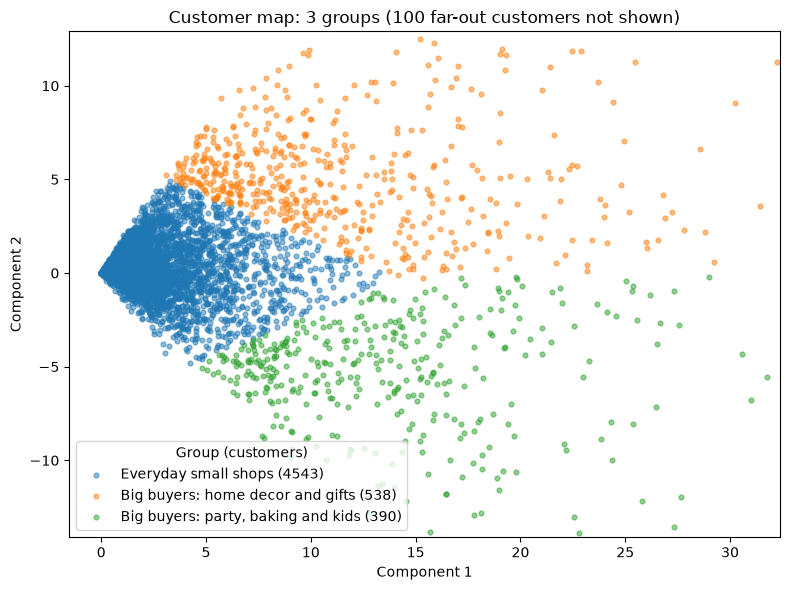

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
cmap = plt.get_cmap("tab10")
for g in range(N_GROUPS):
    pts = Z[labels == g]
    ax.scatter(pts[:, 0], pts[:, 1], s=12, alpha=0.5, color=cmap(g),
               label=f"{name_of(g)} ({len(pts)})")

# zoom in on the bulk of customers, a few very large buyers sit far out
lo, hi = np.percentile(Z, [0.5, 99.5], axis=0)
pad = (hi - lo) * 0.05
ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0])
ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
outside = int(((Z < lo) | (Z > hi)).any(axis=1).sum())
ax.set_xlabel("Component 1")
ax.set_ylabel("Component 2")
ax.set_title(f"Customer map: {N_GROUPS} groups ({outside} far-out customers not shown)")
ax.legend(title="Group (customers)")
plt.tight_layout()
plt.savefig("../outputs/figures/customer_map.png", dpi=150)
plt.show()

## What this shows

Component 1 follows total purchase value (|r| = 0.968), so the map mostly separates small buyers from big buyers. The cone shape is the long tail of big buyers.

The two big-buyer groups are 17% of customers but buy four to five times as many different products as the small shops (200 to 230 against 47). One is home decor and gifts, the other party, baking and kids' items, with more customers outside the UK. The small shops are the big mass in the middle and could get one general campaign.

The silhouette is 0.64 for 3 groups and drops to 0.52 for 6, but a high value here is partly down to the long tail along component 1. The boundaries aren't sharp and 83% of customers sit in one group. Splitting the small shops by what they buy, using more than 2 components, would be a next step. The groups come from past purchases and will change as the data changes.